# 03 · EDA 探索数据（Exploratory Data Analysis）

🍜 **比喻**：开新菜单之前，先把仓库里的食材**一样一样拿出来看**：有多少、新不新鲜、哪些常常一起用。
EDA 就是在建模**之前**先认识数据，避免第三课那种“直线画不出山形”的陷阱。

| 部分 | 要回答的问题 | 影响哪个阶段 |
|---|---|---|
| 1 | 数据长什么样？各联赛、各位置有多少人？ | 全部 |
| 2 | 身价的分布是什么形状？ | 阶段 5 身价模型 |
| 3 | 年龄和身价是什么关系？是山形吗？ | 阶段 5 |
| 4 | 联赛对身价影响多大？ | 阶段 5 |
| 5 | 哪些指标和身价最相关？ | 阶段 5 |
| 6 | 相似度指标之间有没有“重复计算”？ | 阶段 4 相似度 |
| 7 | 中卫的身高 | 阶段 4 |

💡 每一部分最后都有一题 **🤔 思考题**。先自己想，再把答案告诉我，最后一格是让你**填写自己的发现**。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
df = pd.read_csv(ROOT / "data" / "processed" / "players_2025_26.csv")

# 图表风格：浅色背景、淡网格、统一配色（颜色跟着“类别”，不跟着名次）
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c2", "axes.grid": True, "grid.color": "#e8e7e2",
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
})
POS_COLOR = {"FW": "#2a78d6", "MF": "#eb6834", "DF": "#1baf7a"}
LEAGUES = ["ENG-Premier League", "ESP-La Liga", "GER-Bundesliga", "ITA-Serie A", "FRA-Ligue 1"]
LEAGUE_COLOR = dict(zip(LEAGUES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
SHORT = {"ENG-Premier League": "EPL", "ESP-La Liga": "LaLiga", "GER-Bundesliga": "Bundesliga",
         "ITA-Serie A": "Serie A", "FRA-Ligue 1": "Ligue 1"}

print(df.shape)

(1410, 40)


## 1️⃣ 数据概览

`pd.crosstab` 就像一张**交叉统计表**：行是联赛，列是位置，格子里是人数。

In [2]:
display(pd.crosstab(df["league"], df["pos_group"], margins=True, margins_name="Total"))

missing = df.isna().sum()
print("有缺失值的列：")
print(missing[missing > 0])

pos_group,DF,FW,MF,Total
league,,,,
ENG-Premier League,120,85,97,302
ESP-La Liga,119,94,90,303
FRA-Ligue 1,100,65,80,245
GER-Bundesliga,105,66,83,254
ITA-Serie A,121,77,108,306
Total,565,387,458,1410


有缺失值的列：
nation                        1
value_start                   5
contract_expiration_date    113
dtype: int64


## 2️⃣ 身价的分布（Target）

左图是**原始身价**，右图是取了 **log（对数）** 之后的身价。

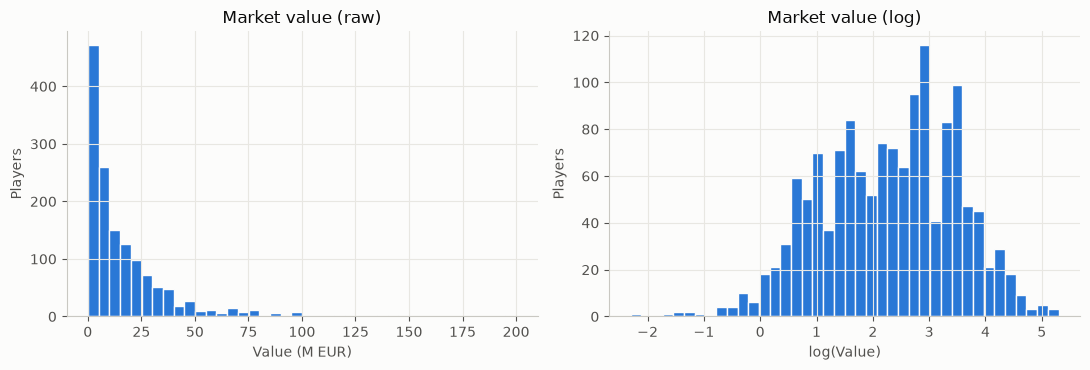

中位数 10.0M，平均数 18.1M
偏度 skewness：原始 3.02 → log 之后 -0.22（越接近 0 越对称）


,player,squad,age,value_end
85,Erling Haaland,Manchester City,25.9,200.0
410,Lamine Yamal,Barcelona,19.0,200.0
235,Kylian Mbappé,Real Madrid,27.5,180.0
389,Michael Olise,Bayern Munich,24.5,150.0
519,Pedri,Barcelona,23.6,150.0


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df["value_end"], bins=40, color="#2a78d6", edgecolor="#fcfcfb")
axes[0].set(title="Market value (raw)", xlabel="Value (M EUR)", ylabel="Players")
axes[1].hist(np.log(df["value_end"]), bins=40, color="#2a78d6", edgecolor="#fcfcfb")
axes[1].set(title="Market value (log)", xlabel="log(Value)", ylabel="Players")
plt.tight_layout(); plt.show()

print(f"中位数 {df.value_end.median():.1f}M，平均数 {df.value_end.mean():.1f}M")
print(f"偏度 skewness：原始 {df.value_end.skew():.2f} → log 之后 {np.log(df.value_end).skew():.2f}（越接近 0 越对称）")
display(df.nlargest(5, "value_end")[["player", "squad", "age", "value_end"]])

🤔 **思考题 1**：原始身价的图形**挤在左边，右边拖着一条长尾巴**（少数 1-2 亿的超级球星）。平均数（约 18M）比中位数（10M）高很多。

如果直接用原始身价训练 Linear Regression，模型会为了少数超级球星拼命调整。为什么取 log 可以解决这个问题？

💡 提示：log 之后，“5M → 10M”和“50M → 100M”的距离是一样的，都是“**翻倍**”。

## 3️⃣ 年龄 vs 身价：真的是山形吗？

第三课我们**假设**身价在 26 岁左右达到高峰。现在用**真实数据**检验。
用**中位数**而不是平均数，避免被 Haaland、Yamal 这种极端值拉高。

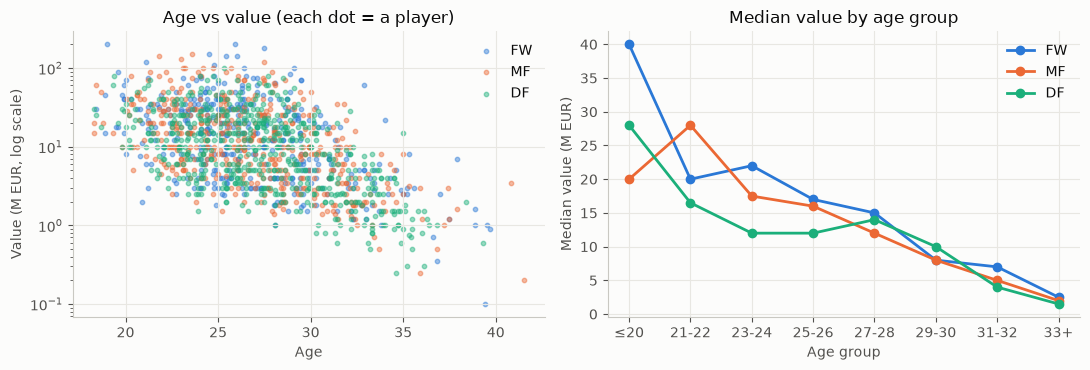

,count,median
age_bin,,
≤20,32,29.0
21-22,100,22.0
23-24,205,15.0
25-26,268,15.0
27-28,267,14.0
29-30,226,8.5
31-32,140,5.0
33+,170,2.0


In [4]:
df["age_bin"] = pd.cut(df["age"], bins=[16, 20, 22, 24, 26, 28, 30, 32, 40],
                       labels=["≤20", "21-22", "23-24", "25-26", "27-28", "29-30", "31-32", "33+"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for pos, c in POS_COLOR.items():
    sub = df[df.pos_group == pos]
    axes[0].scatter(sub["age"], sub["value_end"], s=10, alpha=0.45, color=c, label=pos)
    med = sub.groupby("age_bin", observed=True)["value_end"].median()
    axes[1].plot(med.index.astype(str), med.values, marker="o", lw=2, color=c, label=pos)
axes[0].set(yscale="log", title="Age vs value (each dot = a player)", xlabel="Age", ylabel="Value (M EUR, log scale)")
axes[1].set(title="Median value by age group", xlabel="Age group", ylabel="Median value (M EUR)")
for ax in axes: ax.legend(frameon=False)
plt.tight_layout(); plt.show()

display(df.groupby("age_bin", observed=True)["value_end"].agg(["count", "median"]).round(1))

🤔 **思考题 2**：右图**不是山形**，而是从年轻人开始**一路下降**。这和第三课的假设不同！

为什么在**我们这份数据**里，20 岁的球员中位数反而最高？

💡 提示：我们只保留了“**在五大联赛踢满 900 分钟以上**”的球员。一个 20 岁的球员要做到这一点，他通常是什么样的球员？
被过滤掉的那些 20 岁球员又去了哪里？（关键词：**Survivorship Bias 幸存者偏差**）

## 4️⃣ 联赛对身价的影响

箱形图（box plot）怎么看：箱子中间的线是**中位数**，箱子是中间 50% 的球员，点是离群值。

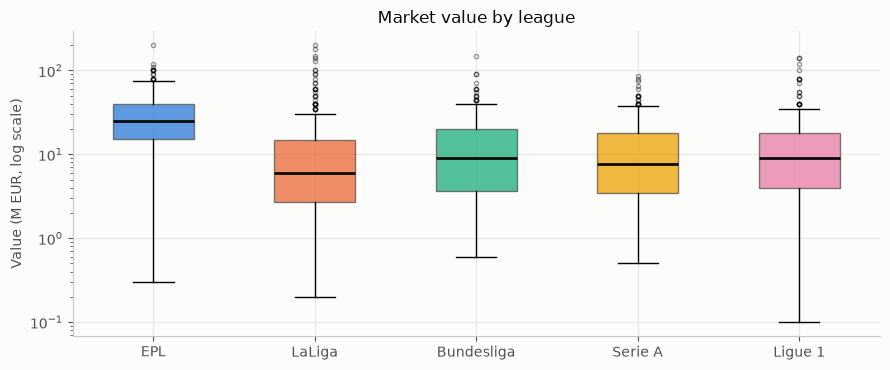

,count,median,mean
league,,,
ENG-Premier League,302,25.0,31.8
FRA-Ligue 1,245,9.0,14.8
GER-Bundesliga,254,9.0,15.1
ITA-Serie A,306,7.8,13.3
ESP-La Liga,303,6.0,14.3


In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
data = [df.loc[df.league == lg, "value_end"] for lg in LEAGUES]
bp = ax.boxplot(data, tick_labels=[SHORT[l] for l in LEAGUES], patch_artist=True,
                medianprops={"color": "#0b0b0b", "lw": 2}, flierprops={"markersize": 3, "alpha": 0.4})
for patch, lg in zip(bp["boxes"], LEAGUES):
    patch.set(facecolor=LEAGUE_COLOR[lg], alpha=0.75, edgecolor="#52514e")
ax.set(yscale="log", title="Market value by league", ylabel="Value (M EUR, log scale)")
plt.tight_layout(); plt.show()

display(df.groupby("league")["value_end"].agg(["count", "median", "mean"]).round(1).sort_values("median", ascending=False))

🤔 **思考题 3**：英超的中位数大约是其他联赛的 **3 倍**。

假设一名西甲球员和一名英超球员的**所有表现数据都一模一样**。你的身价模型会怎么估他们的价钱？
对于你的“平替”系统来说，这其实是**好消息还是坏消息**？

💡 提示：想想“被低估”的定义。

## 5️⃣ 哪些指标和身价最相关？

**相关系数（correlation）**：-1 到 1。正数 = 一起上升，负数 = 一个升另一个降，0 = 没关系。
这里用 **log(身价)** 来计算，原因见思考题 1。

⚠️ 相关系数只能看出**直线关系**，而且**相关 ≠ 因果**。

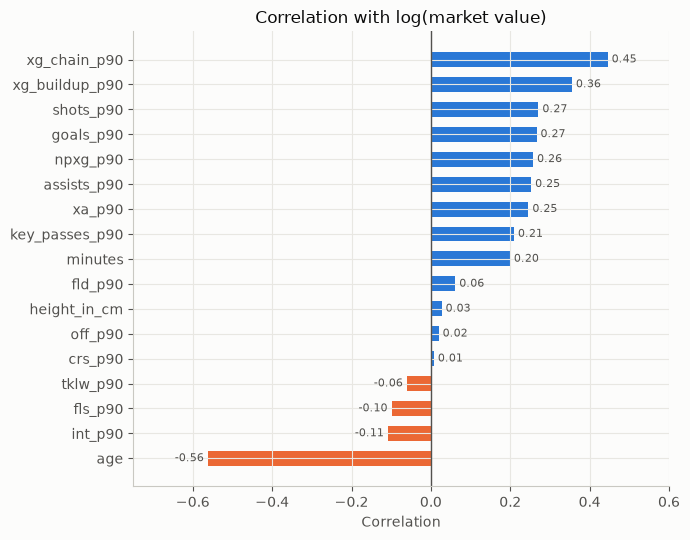

赛季开始时身价 value_start 与 log(value_end) 的相关： 0.79


In [6]:
feats = [c for c in df.columns if c.endswith("_p90")] + ["age", "minutes", "height_in_cm"]
corr = df[feats].corrwith(np.log(df["value_end"])).sort_values()

fig, ax = plt.subplots(figsize=(7, 5.5))
colors = ["#eb6834" if v < 0 else "#2a78d6" for v in corr.values]
ax.barh(corr.index, corr.values, color=colors, height=0.6)
ax.axvline(0, color="#52514e", lw=1)
ax.set(title="Correlation with log(market value)", xlabel="Correlation", xlim=(-0.75, 0.6))
for y, v in enumerate(corr.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), y, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

print("赛季开始时身价 value_start 与 log(value_end) 的相关：",
      round(np.log(df["value_start"].clip(lower=0.01)).corr(np.log(df["value_end"])), 2))

🤔 **思考题 4**：

- **(a)** 拦截（`int_p90`）、犯规（`fls_p90`）和身价是**负相关**。难道防守越多，身价越低？还是有别的原因？
  💡 提示：哪个**位置**的拦截最多？哪个位置的身价通常最高？
- **(b)** `value_start`（赛季开始时的身价）和赛季结束身价的相关高达约 0.8。如果把它放进模型，准确率一定会大幅提高。
  但这样做有什么问题？你的系统是要找出“**被市场低估**”的球员 🤔

## 6️⃣ 相似度指标之间的“重复计算”（Multicollinearity）

还记得第一课说的吗？射门多的人 xG 通常也高，两个都放进相似度计算，等于**同一件事算两次**。
下面按**每个位置的指标方案**画出相关矩阵：**颜色越深 = 越相关**。

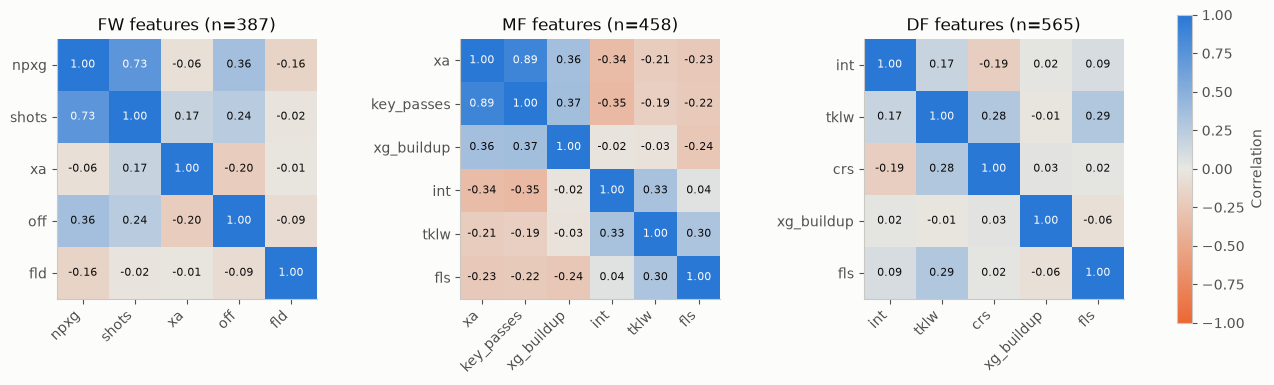

FW 高度相关（> 0.7）： [('npxg_p90', 'shots_p90', np.float64(0.73))]
MF 高度相关（> 0.7）： [('xa_p90', 'key_passes_p90', np.float64(0.89))]
DF 高度相关（> 0.7）： 无


In [7]:
FEATURES = {
    "FW": ["npxg_p90", "shots_p90", "xa_p90", "off_p90", "fld_p90"],
    "MF": ["xa_p90", "key_passes_p90", "xg_buildup_p90", "int_p90", "tklw_p90", "fls_p90"],
    "DF": ["int_p90", "tklw_p90", "crs_p90", "xg_buildup_p90", "fls_p90"],
}
from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list("div", ["#eb6834", "#e8e7e2", "#2a78d6"])

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"wspace": 0.55})
for ax, (pos, cols) in zip(axes, FEATURES.items()):
    m = df[df.pos_group == pos][cols].corr()
    im = ax.imshow(m, cmap=diverging, vmin=-1, vmax=1)
    labels = [c.replace("_p90", "") for c in cols]
    ax.set_xticks(range(len(cols)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(cols)), labels)
    ax.grid(False)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="#fcfcfb" if abs(m.iloc[i, j]) > 0.6 else "#0b0b0b")
    ax.set_title(f"{pos} features (n={int((df.pos_group == pos).sum())})")
fig.colorbar(im, ax=axes, shrink=0.8, pad=0.04, label="Correlation")
plt.show()

# 自动列出相关 > 0.7 的指标对
for pos, cols in FEATURES.items():
    m = df[df.pos_group == pos][cols].corr()
    pairs = [(a, b, round(m.loc[a, b], 2)) for i, a in enumerate(cols) for b in cols[i + 1:] if abs(m.loc[a, b]) > 0.7]
    print(pos, "高度相关（> 0.7）：", pairs or "无")

🤔 **思考题 5**：如果某个位置有一对指标相关 > 0.7，你会怎么处理？
删掉其中一个？保留两个但**降低权重**？还是没关系？说说你的理由。

💡 提示：回想 Cosine Similarity 是怎么算“像不像”的：每个指标都是一个方向，**两个几乎相同的方向会让那件事的影响变成两倍**。

## 7️⃣ 中卫的身高（争顶的近似指标）

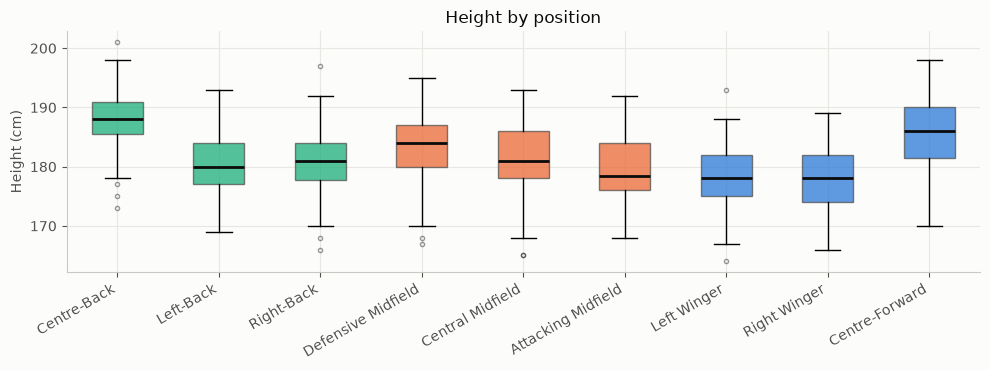

sub_position
Centre-Back           188.0
Centre-Forward        186.0
Defensive Midfield    184.0
Central Midfield      181.0
Right-Back            181.0
Right Midfield        181.0
Left-Back             180.0
Left Midfield         179.0
Attacking Midfield    178.5
Left Winger           178.0
Right Winger          178.0
Second Striker        176.0
Name: height_in_cm, dtype: float64

In [8]:
order = ["Centre-Back", "Left-Back", "Right-Back", "Defensive Midfield", "Central Midfield",
         "Attacking Midfield", "Left Winger", "Right Winger", "Centre-Forward"]
sub = df[df.sub_position.isin(order)]
fig, ax = plt.subplots(figsize=(10, 3.8))
bp = ax.boxplot([sub.loc[sub.sub_position == p, "height_in_cm"].dropna() for p in order],
                tick_labels=order, patch_artist=True,
                medianprops={"color": "#0b0b0b", "lw": 2}, flierprops={"markersize": 3, "alpha": 0.4})
for patch, p in zip(bp["boxes"], order):
    patch.set(facecolor=POS_COLOR[df.loc[df.sub_position == p, "pos_group"].iloc[0]], alpha=0.75, edgecolor="#52514e")
ax.set(title="Height by position", ylabel="Height (cm)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

display(df.groupby("sub_position")["height_in_cm"].median().sort_values(ascending=False))

🤔 **思考题 6**：中卫是最高的位置之一，这支持“身高可以当作争顶能力的近似指标”吗？
有没有反例？（例如很高但不擅长争顶的球员，或不高但很会争顶的球员）这点要写进报告的 *Limitations*。

## 📝 我的发现（自己填）

把你对 6 道思考题的答案整理成**对后面阶段的决定**，这一段之后可以直接改写成 FYP 报告的 EDA 章节。

| # | 发现 | 对阶段 4 / 5 的决定 |
|---|---|---|
| 1 | 身价分布 … | |
| 2 | 年龄 … | |
| 3 | 联赛 … | |
| 4 | 相关性 … | |
| 5 | 重复计算 … | |
| 6 | 身高 … | |